In [163]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Optional (recommended for quick EDA plots)
import seaborn as sns


In [164]:
df = pd.read_csv(r"superstore.csv")
df.head()

,Category,City,Country,Customer.ID,Customer.Name,Discount,Market,记录数,Order.Date,Order.ID,...,Sales,Segment,Ship.Date,Ship.Mode,Shipping.Cost,State,Sub.Category,Year,Market2,weeknum
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,1,00:00.0,CA-2011-130813,...,19,Consumer,00:00.0,Second Class,4.37,California,Paper,2011,North America,2
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,1,00:00.0,CA-2011-148614,...,19,Consumer,00:00.0,Standard Class,0.94,California,Paper,2011,North America,4
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,00:00.0,CA-2011-118962,...,21,Consumer,00:00.0,Standard Class,1.81,California,Paper,2011,North America,32
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,00:00.0,CA-2011-118962,...,111,Consumer,00:00.0,Standard Class,4.59,California,Paper,2011,North America,32
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.0,US,1,00:00.0,CA-2011-146969,...,6,Consumer,00:00.0,Standard Class,1.32,California,Paper,2011,North America,40


#### Q1: Data Cleaning: 

##### i.  Count and handle Missing values.

df.isnull().sum()

In [165]:
#df.isnull().sum()
df.isna().sum()

Category          0
City              0
Country           0
Customer.ID       0
Customer.Name     0
Discount          0
Market            0
记录数               0
Order.Date        0
Order.ID          0
Order.Priority    0
Product.ID        0
Product.Name      0
Profit            0
Quantity          0
Region            0
Row.ID            0
Sales             0
Segment           0
Ship.Date         0
Ship.Mode         0
Shipping.Cost     5
State             3
Sub.Category      0
Year              0
Market2           0
weeknum           0
dtype: int64

###### check for missing Shipping costs

In [166]:
#df[df['Shipping.Cost'].notnull()]
#missing values in shipping cost by product ID
df[df['Shipping.Cost'].isna()]['Product.ID']

448     OFF-AR-10000817
605     OFF-PA-10000675
854     OFF-PA-10000174
1265    OFF-ST-10002276
1465    OFF-AR-10004587
Name: Product.ID, dtype: object

In [167]:
# replace missing values with group means
df['Shipping.Cost'] = df['Shipping.Cost'].fillna(df.groupby(['Product.ID', 'Year'])['Shipping.Cost'].transform('mean'))
df['Shipping.Cost'] = df['Shipping.Cost'].fillna(df.groupby('Product.ID')['Shipping.Cost'].transform('mean'))
df[df['Shipping.Cost'].isna()]['Product.ID']


Series([], Name: Product.ID, dtype: object)

###### check for missing States

In [168]:
df[df['State'].isna()]

,Category,City,Country,Customer.ID,Customer.Name,Discount,Market,记录数,Order.Date,Order.ID,...,Sales,Segment,Ship.Date,Ship.Mode,Shipping.Cost,State,Sub.Category,Year,Market2,weeknum
1439,Office Supplies,Seattle,United States,LL-168404,Lauren Leatherbury,0.0,US,1,00:00.0,CA-2012-164833,...,9,Consumer,00:00.0,Same Day,1.82,NaN,Art,2012,North America,23
1440,Office Supplies,Seattle,United States,LL-168404,Lauren Leatherbury,0.0,US,1,00:00.0,CA-2012-164833,...,7,Consumer,00:00.0,Same Day,1.56,NaN,Labels,2012,North America,23
1452,Office Supplies,Seattle,United States,SG-200804,Sandra Glassco,0.0,US,1,00:00.0,CA-2012-162544,...,5,Consumer,00:00.0,First Class,0.09,NaN,Paper,2012,North America,51


In [169]:
#replace City having Seattle with Washington as state due this pattern
df['State'] = np.where((df['City']=='Seattle') & (df['State'].isna()),'Washington',df['State'])
df[df['State'].isna()]

,Category,City,Country,Customer.ID,Customer.Name,Discount,Market,记录数,Order.Date,Order.ID,...,Sales,Segment,Ship.Date,Ship.Mode,Shipping.Cost,State,Sub.Category,Year,Market2,weeknum


##### ii. Deal with Duplicate values 

In [170]:
df[df.duplicated()]
#df.drop_duplicates(subset=[], keep='last', inplace=True)

,Category,City,Country,Customer.ID,Customer.Name,Discount,Market,记录数,Order.Date,Order.ID,...,Sales,Segment,Ship.Date,Ship.Mode,Shipping.Cost,State,Sub.Category,Year,Market2,weeknum


##### iii. Delete unknown columns if present. 

In [171]:
col_to_drop = df.columns[7]
df.drop(columns = col_to_drop, inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 26 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Category        51290 non-null  object 
 1   City            51290 non-null  object 
 2   Country         51290 non-null  object 
 3   Customer.ID     51290 non-null  object 
 4   Customer.Name   51290 non-null  object 
 5   Discount        51290 non-null  float64
 6   Market          51290 non-null  object 
 7   Order.Date      51290 non-null  object 
 8   Order.ID        51290 non-null  object 
 9   Order.Priority  51290 non-null  object 
 10  Product.ID      51290 non-null  object 
 11  Product.Name    51290 non-null  object 
 12  Profit          51290 non-null  float64
 13  Quantity        51290 non-null  int64  
 14  Region          51290 non-null  object 
 15  Row.ID          51290 non-null  int64  
 16  Sales           51290 non-null  int64  
 17  Segment         51290 non-null 

##### iv. Check shape, size, and datatypes of the dataset features.

In [172]:
df.shape

(51290, 26)

In [173]:
df['Order.Date'] = pd.to_datetime(df['Order.Date'])
df['Ship.Date'] = pd.to_datetime(df['Ship.Date'])

In [174]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 26 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Category        51290 non-null  object        
 1   City            51290 non-null  object        
 2   Country         51290 non-null  object        
 3   Customer.ID     51290 non-null  object        
 4   Customer.Name   51290 non-null  object        
 5   Discount        51290 non-null  float64       
 6   Market          51290 non-null  object        
 7   Order.Date      51290 non-null  datetime64[ns]
 8   Order.ID        51290 non-null  object        
 9   Order.Priority  51290 non-null  object        
 10  Product.ID      51290 non-null  object        
 11  Product.Name    51290 non-null  object        
 12  Profit          51290 non-null  float64       
 13  Quantity        51290 non-null  int64         
 14  Region          51290 non-null  object        
 15  Ro

#### Q2: Perform Univariate Analysis across all numerical features,

##### data prep

In [175]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
date_cols  = df.select_dtypes(include=["datetime64[ns]", "datetime64[ns, UTC]"]).columns.tolist()

num_cols, cat_cols, date_cols

(['Discount',
  'Profit',
  'Quantity',
  'Row.ID',
  'Sales',
  'Shipping.Cost',
  'Year',
  'weeknum'],
 ['Category',
  'City',
  'Country',
  'Customer.ID',
  'Customer.Name',
  'Market',
  'Order.ID',
  'Order.Priority',
  'Product.ID',
  'Product.Name',
  'Region',
  'Segment',
  'Ship.Mode',
  'State',
  'Sub.Category',
  'Market2'],
 ['Order.Date', 'Ship.Date'])

 ##### i.            Which features seem useless in the analysis? Explain why? 

In [176]:
df[num_cols].describe()

,Discount,Profit,Quantity,Row.ID,Sales,Shipping.Cost,Year,weeknum
count,51290.000000,51290.000000,51290.000000,51290.00000,51290.000000,51290.000000,51290.000000,51290.000000
mean,0.142908,28.610982,3.476545,25645.50000,246.498440,26.376324,2012.777208,31.287112
std,0.212280,174.340972,2.278766,14806.29199,487.567175,57.296683,1.098931,14.429795
min,0.000000,-6599.978000,1.000000,1.00000,0.000000,0.002000,2011.000000,1.000000
25%,0.000000,0.000000,2.000000,12823.25000,31.000000,2.610000,2012.000000,20.000000
50%,0.000000,9.240000,3.000000,25645.50000,85.000000,7.790000,2013.000000,33.000000
75%,0.200000,36.810000,5.000000,38467.75000,251.000000,24.450000,2014.000000,44.000000
max,0.850000,8399.976000,14.000000,51290.00000,22638.000000,933.570000,2014.000000,53.000000


In [177]:
df[date_cols].describe()

,Order.Date,Ship.Date
count,51290,51290
mean,2026-10-06 00:00:00,2026-10-06 00:00:00
min,2026-10-06 00:00:00,2026-10-06 00:00:00
25%,2026-10-06 00:00:00,2026-10-06 00:00:00
50%,2026-10-06 00:00:00,2026-10-06 00:00:00
75%,2026-10-06 00:00:00,2026-10-06 00:00:00
max,2026-10-06 00:00:00,2026-10-06 00:00:00


ANSWER: date colums are useless

##### ii.            Which features are uniformly distributed or normally distributed? 

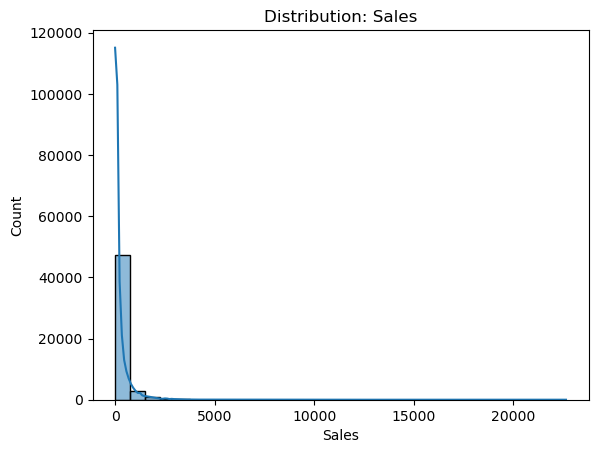

In [178]:
example_num = num_cols[4] if num_cols else None
if example_num:
    sns.histplot(df[example_num], bins=30, kde=True)
    plt.title(f"Distribution: {example_num}")
    plt.show()
else:
    print("No numeric columns to plot.")

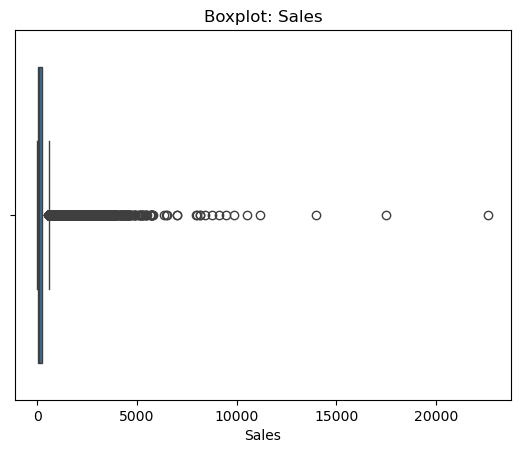

In [179]:
if example_num:
    sns.boxplot(x=df[example_num])
    plt.title(f"Boxplot: {example_num}")
    plt.show()

##### iii.            Which features are right-skewed/left-skewed? What does this signify?

In [180]:
if example_num:
    print("skew:", df[example_num].skew())
    print("kurtosis:", df[example_num].kurt())

skew: 8.137980509722208
kurtosis: 176.7230230013565


##### iv.            Which features have a high number of outliers, and discuss the impact.

In [181]:
def iqr_outliers(data: pd.Series):
    s = data.dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (data < lower) | (data > upper)
    return lower, upper, mask

if example_num:
    lower, upper, mask = iqr_outliers(df[example_num])
    print("IQR bounds:", lower, upper)
    print("Outliers:", mask.sum(), f"({mask.mean()*100:.2f}%)")
    df.loc[mask, [example_num]].head(10)

IQR bounds: -299.0 581.0
Outliers: 5655 (11.03%)


#### Q 3: Perform Univariate Analysis across all categorical features. 

##### i. Which features seem inaccurate and are not useful as categorical “insights” directly? 

,count,Sales
Segment,,
Corporate,15429,247.897336
Home Office,9343,247.239217
Consumer,26518,245.423524


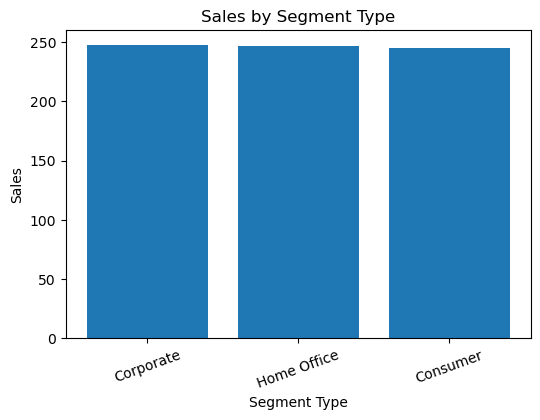

In [182]:
#category analysis

summary = df.groupby('Segment')['Sales'].agg(['count', 'mean']).sort_values('mean', ascending = False)
summary = summary.rename(columns = {'mean': 'Sales'})
display(summary)

plt.figure(figsize = (6, 4))
plt.bar(summary.index.astype(str), summary['Sales'].values)
plt.title("Sales by Segment Type")
plt.xlabel("Segment Type")
plt.ylabel("Sales")
plt.xticks(rotation = 20)
plt.show()

ANSWER: Segment is not useful and seems inaccurate

##### ii. What’s the issue with treating Customer Name as a categorical feature for modeling?

ANSWER: Too much categories when using Customer name as category

##### iii. Is the Category distribution balanced or skewed? Give a 1-line reason.

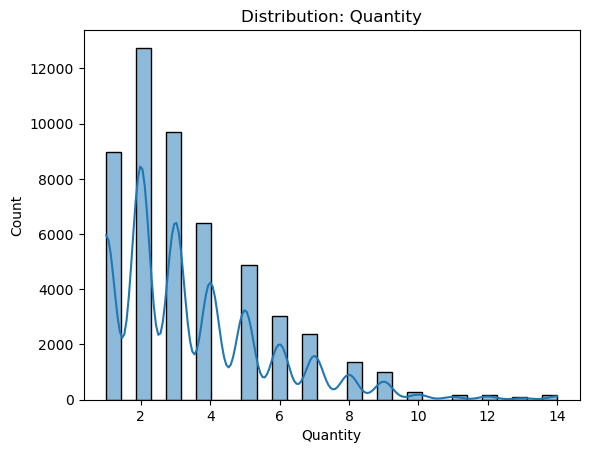

skew: 1.3603677307024207
kurtosis: 2.2758887299856605


In [183]:
# Pick a numeric column to explore
example_num = num_cols[2] if num_cols else None
example_num
if example_num:
    sns.histplot(df[example_num], bins=30, kde=True)
    plt.title(f"Distribution: {example_num}")
    plt.show()
else:
    print("No numeric columns to plot.")
if example_num:
    print("skew:", df[example_num].skew())
    print("kurtosis:", df[example_num].kurt())

Quantity is skewed to 1 to 3 quantities.

##### iv. In Country, does one country dominate strongly? What does that imply about geographic bias? 

In [184]:
# top 10 countries by total sales
group_col = "country" if "country" in df.columns else (cat_cols[2] if cat_cols else None)
metric = "sales" if "sales" in df.columns else (num_cols[4] if num_cols else None)

if group_col and metric:
    topN = (
        df.groupby(group_col, dropna=False)[metric]
          .sum()
          .sort_values(ascending=False)
          .head(10)
          .reset_index(name=f"total_{metric}")
    )
    display(topN)
else:
    print("Need a categorical group column and a numeric metric for grouped Top-N.")

,Country,total_Sales
0,United States,2297354
1,Australia,925257
2,France,858930
3,China,700591
4,Germany,628857
5,Mexico,622620
6,India,589664
7,United Kingdom,528570
8,Indonesia,404887
9,Brazil,361098


yes. it is concentrated to 1 country  United states

##### v. Is the City dataset concentrated in a few cities or spread out? 

In [185]:
# top 10 cities by total sales
group_col = "country" if "country" in df.columns else (cat_cols[1] if cat_cols else None)
metric = "sales" if "sales" in df.columns else (num_cols[4] if num_cols else None)

if group_col and metric:
    topN = (
        df.groupby(group_col, dropna=False)[metric]
          .sum()
          .sort_values(ascending=False)
          .head(10)
          .reset_index(name=f"total_{metric}")
    )
    display(topN)
else:
    print("Need a categorical group column and a numeric metric for grouped Top-N.")

,City,total_Sales
0,New York City,256397
1,Los Angeles,175857
2,Manila,120896
3,Seattle,119552
4,San Francisco,112690
5,Philadelphia,109085
6,Sydney,101952
7,Jakarta,94318
8,London,86945
9,Mexico City,85732


yes. it is concentrated to 2 cities New york and Los Angeles

#### Q 4: Perform Bivariant Analysis for numerical-to-numerical features: 

In [186]:
corr_matrix= df[num_cols].corr()

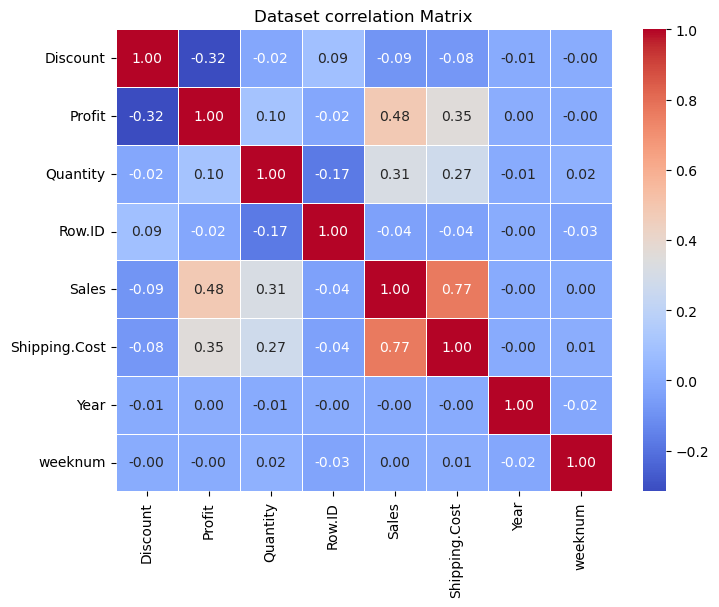

In [187]:
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Dataset correlation Matrix')
plt.show()

##### i. Which two features are most strongly correlated?

In [188]:
# Choose two numeric columns for an example
if len(num_cols) >= 2:
    x, y = num_cols[1], num_cols[4]
    print("Using:", x, "vs", y)
else:
    x = y = None

Using: Profit vs Sales


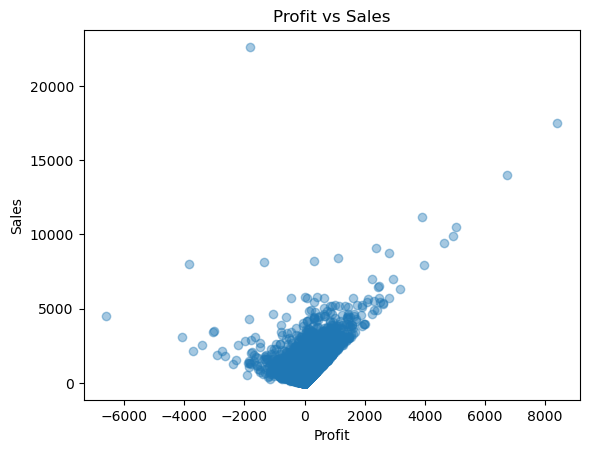

In [189]:
if x and y:
    plt.scatter(df[x], df[y], alpha=0.4)
    plt.xlabel(x)
    plt.ylabel(y)
    plt.title(f"{x} vs {y}")
    plt.show()

##### ii Also name features that are negatively correlated. 

Using: Discount vs Profit


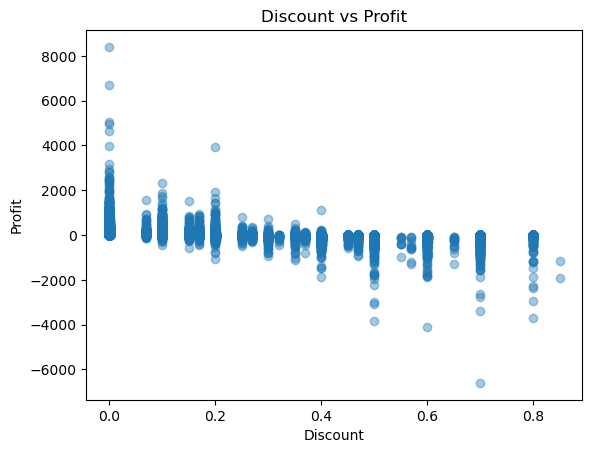

In [190]:
# Choose two numeric columns for an example
if len(num_cols) >= 2:
    x, y = num_cols[0], num_cols[1]
    print("Using:", x, "vs", y)
else:
    x = y = None

if x and y:
    plt.scatter(df[x], df[y], alpha=0.4)
    plt.xlabel(x)
    plt.ylabel(y)
    plt.title(f"{x} vs {y}")
    plt.show()

##### iii. If your goal is to understand profit, which are the most useful next bivariate checks? 
##### Perform them and give clear insights.

Using: Profit vs Shipping.Cost


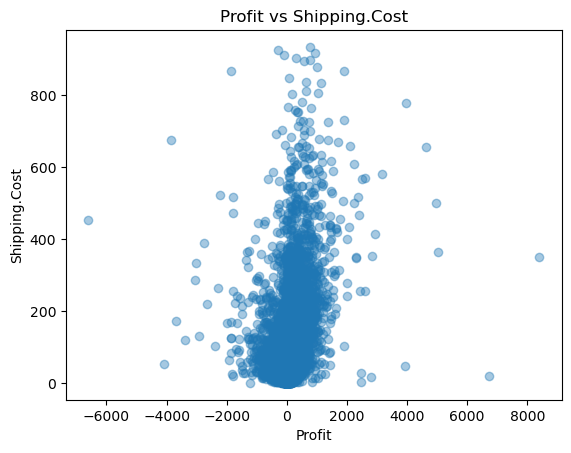

In [191]:
# Choose two numeric columns for an example
if len(num_cols) >= 2:
    x, y = num_cols[1], num_cols[5]
    print("Using:", x, "vs", y)
else:
    x = y = None

if x and y:
    plt.scatter(df[x], df[y], alpha=0.4)
    plt.xlabel(x)
    plt.ylabel(y)
    plt.title(f"{x} vs {y}")
    plt.show()

##### iv. Look for Time Effects Clues. Mention any information you find about the time relationship with any feature. 

Using: Year vs Shipping.Cost


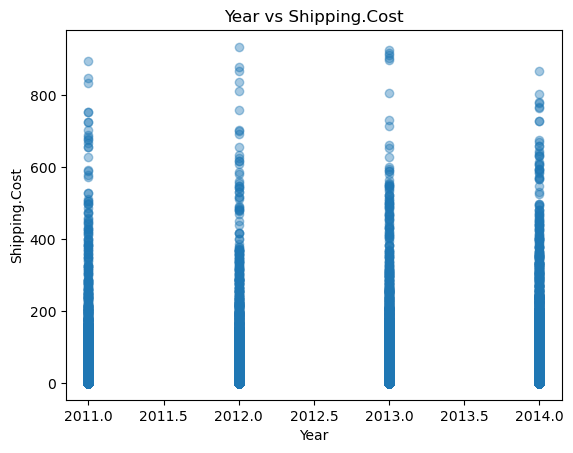

In [192]:
# Choose two numeric columns for an example
if len(num_cols) >= 2:
    x, y = num_cols[6], num_cols[5]
    print("Using:", x, "vs", y)
else:
    x = y = None

if x and y:
    plt.scatter(df[x], df[y], alpha=0.4)
    plt.xlabel(x)
    plt.ylabel(y)
    plt.title(f"{x} vs {y}")
    plt.show()

#### Q 5: Perform Bi-variant Analysis for categorical to numerical features.: 

##### i. Profit by Category: Which category has the highest median profit? Which has the lowest? Which category shows the widest spread (largest IQR) in Profit? What does that suggest about profit consistency? 

In [193]:
# Pick one categorical and one numeric column (example)
example_cat = cat_cols[0] if cat_cols else None
example_num = num_cols[1] if num_cols else None
example_cat, example_num

('Category', 'Profit')

In [194]:
#outliers
def iqr_outliers(data: pd.Series):
    s = data.dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (data < lower) | (data > upper)
    return lower, upper, mask

if example_num:
    lower, upper, mask = iqr_outliers(df[example_num])
    print("IQR bounds:", lower, upper)
    print("Outliers:", mask.sum(), f"({mask.mean()*100:.2f}%)")
    df.loc[mask, [example_num]].head(10)

IQR bounds: -55.215 92.025
Outliers: 9755 (19.02%)


In [195]:
df[example_num] = df[example_num].clip(lower, upper)

# Example: log transform (works only if values are >= 0; use log1p to handle zeros)
# df[example_num + "_log"] = np.log1p(df[example_num])

In [196]:
if example_cat and example_num:
    summary = (
        df.groupby(example_cat)[example_num]
          .agg(["count", "mean", "median", "std", "min", "max"])
          .sort_values("mean", ascending=False)
    )
    display(summary)

,count,mean,median,std,min,max
Category,,,,,,
Technology,10141,31.785051,29.9400,50.399900,-55.215,92.025
Furniture,9876,21.579684,15.5022,49.988483,-55.215,92.025
Office Supplies,31273,12.551022,6.5538,29.944055,-55.215,92.025


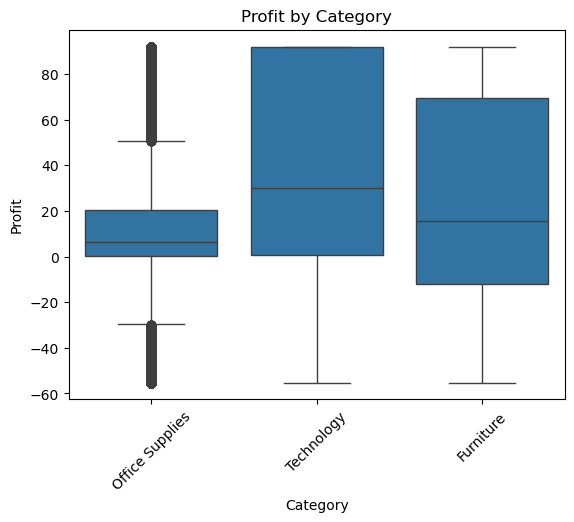

In [197]:
if example_cat and example_num:
    sns.boxplot(data=df, x=example_cat, y=example_num)
    plt.xticks(rotation=45)
    plt.title(f"{example_num} by {example_cat}")
    plt.show()

##### ii. Sales by Category: Which category has the highest median sales? Does it also have the highest median profit? 

In [198]:
# Pick one categorical and one numeric column (example)
example_cat = cat_cols[0] if cat_cols else None
example_num = num_cols[4] if num_cols else None
example_cat, example_num

('Category', 'Sales')

In [199]:
#outliers
def iqr_outliers(data: pd.Series):
    s = data.dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (data < lower) | (data > upper)
    return lower, upper, mask

if example_num:
    lower, upper, mask = iqr_outliers(df[example_num])
    print("IQR bounds:", lower, upper)
    print("Outliers:", mask.sum(), f"({mask.mean()*100:.2f}%)")
    df.loc[mask, [example_num]].head(10)

IQR bounds: -299.0 581.0
Outliers: 5655 (11.03%)


In [200]:
df[example_num] = df[example_num].clip(lower, upper)

# Example: log transform (works only if values are >= 0; use log1p to handle zeros)
# df[example_num + "_log"] = np.log1p(df[example_num])

In [201]:
if example_cat and example_num:
    summary = (
        df.groupby(example_cat)[example_num]
          .agg(["count", "mean", "median", "std", "min", "max"])
          .sort_values("mean", ascending=False)
    )
    display(summary)

,count,mean,median,std,min,max
Category,,,,,,
Technology,10141,303.413963,260.0,202.668756,1,581
Furniture,9876,278.840320,220.0,207.197919,2,581
Office Supplies,31273,96.156653,46.0,131.760859,0,581


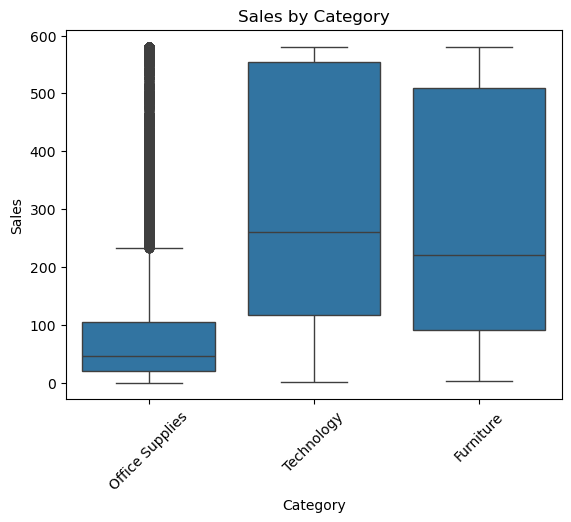

In [202]:
if example_cat and example_num:
    sns.boxplot(data=df, x=example_cat, y=example_num)
    plt.xticks(rotation=45)
    plt.title(f"{example_num} by {example_cat}")
    plt.show()

##### iii. Profit by Segment: Which segment has the highest median profit? Which segment has the most negative/low profit outliers? 

In [203]:
# Pick one categorical and one numeric column (example)
example_cat = cat_cols[11] if cat_cols else None
example_num = num_cols[1] if num_cols else None
example_cat, example_num

('Segment', 'Profit')

In [204]:
#outliers
def iqr_outliers(data: pd.Series):
    s = data.dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (data < lower) | (data > upper)
    return lower, upper, mask

if example_num:
    lower, upper, mask = iqr_outliers(df[example_num])
    print("IQR bounds:", lower, upper)
    print("Outliers:", mask.sum(), f"({mask.mean()*100:.2f}%)")
    df.loc[mask, [example_num]].head(10)

IQR bounds: -55.215 92.025
Outliers: 0 (0.00%)


In [205]:
df[example_num] = df[example_num].clip(lower, upper)

# Example: log transform (works only if values are >= 0; use log1p to handle zeros)
# df[example_num + "_log"] = np.log1p(df[example_num])

In [206]:
if example_cat and example_num:
    summary = (
        df.groupby(example_cat)[example_num]
          .agg(["count", "mean", "median", "std", "min", "max"])
          .sort_values("mean", ascending=False)
    )
    display(summary)

,count,mean,median,std,min,max
Segment,,,,,,
Home Office,9343,18.539858,9.3200,40.035849,-55.215,92.025
Corporate,15429,18.093925,9.3152,39.823903,-55.215,92.025
Consumer,26518,17.933939,9.1800,39.803049,-55.215,92.025


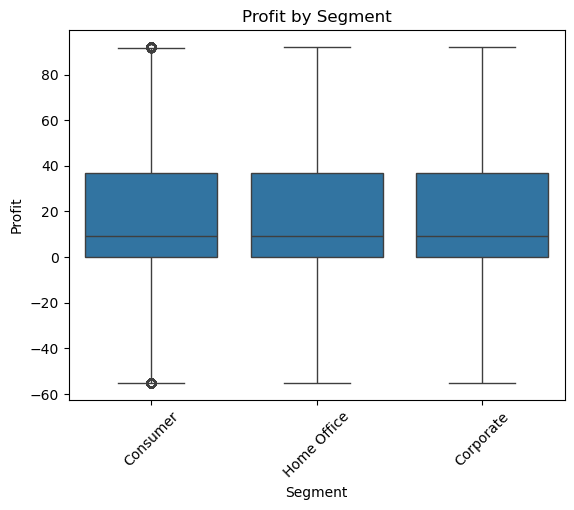

In [207]:
if example_cat and example_num:
    sns.boxplot(data=df, x=example_cat, y=example_num)
    plt.xticks(rotation=45)
    plt.title(f"{example_num} by {example_cat}")
    plt.show()

##### iv. Sales by Segment: Which segment has the highest median sales? Is the profit pattern consistent with sales?

In [208]:
# Pick one categorical and one numeric column (example)
example_cat = cat_cols[11] if cat_cols else None
example_num = num_cols[4] if num_cols else None
example_cat, example_num

('Segment', 'Sales')

In [209]:
#outliers
def iqr_outliers(data: pd.Series):
    s = data.dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (data < lower) | (data > upper)
    return lower, upper, mask

if example_num:
    lower, upper, mask = iqr_outliers(df[example_num])
    print("IQR bounds:", lower, upper)
    print("Outliers:", mask.sum(), f"({mask.mean()*100:.2f}%)")
    df.loc[mask, [example_num]].head(10)

IQR bounds: -299.0 581.0
Outliers: 0 (0.00%)


In [210]:
df[example_num] = df[example_num].clip(lower, upper)

# Example: log transform (works only if values are >= 0; use log1p to handle zeros)
# df[example_num + "_log"] = np.log1p(df[example_num])

In [211]:
if example_cat and example_num:
    summary = (
        df.groupby(example_cat)[example_num]
          .agg(["count", "mean", "median", "std", "min", "max"])
          .sort_values("mean", ascending=False)
    )
    display(summary)

,count,mean,median,std,min,max
Segment,,,,,,
Corporate,15429,173.371832,85.0,190.759427,1,581
Consumer,26518,171.948299,85.0,189.462613,0,581
Home Office,9343,171.591138,85.0,190.157421,1,581


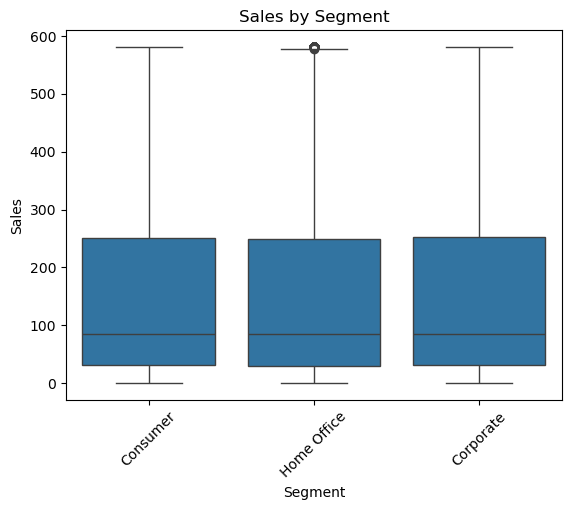

In [212]:
if example_cat and example_num:
    sns.boxplot(data=df, x=example_cat, y=example_num)
    plt.xticks(rotation=45)
    plt.title(f"{example_num} by {example_cat}")
    plt.show()

#### Q 6: Perform Bivariate Analysis for Market features against Region, Category, and Country:

##### i. Is the Market is not randomly spread across all Regions? 

###### Bivariate Analysis country and category

In [213]:
if len(cat_cols) >= 2:
    c1, c2 = cat_cols[2], cat_cols[0]
    display(pd.crosstab(df[c1], df[c2]))
    display(pd.crosstab(df[c1], df[c2], normalize="index"))
else:
    print("Need at least 2 categorical columns for this section.")

Category,Furniture,Office Supplies,Technology
Country,,,
Afghanistan,13,30,12
Albania,3,9,4
Algeria,26,136,34
Angola,20,81,21
Argentina,91,220,79
...,...,...,...
Venezuela,35,125,34
Vietnam,63,141,61
Yemen,5,19,6


Category,Furniture,Office Supplies,Technology
Country,,,
Afghanistan,0.236364,0.545455,0.218182
Albania,0.187500,0.562500,0.250000
Algeria,0.132653,0.693878,0.173469
Angola,0.163934,0.663934,0.172131
Argentina,0.233333,0.564103,0.202564
...,...,...,...
Venezuela,0.180412,0.644330,0.175258
Vietnam,0.237736,0.532075,0.230189
Yemen,0.166667,0.633333,0.200000


Answer: not random

###### Bivariate Analysis Region and category 

In [214]:
if len(cat_cols) >= 2:
    c1, c2 = cat_cols[10], cat_cols[0]
    display(pd.crosstab(df[c1], df[c2]))
    display(pd.crosstab(df[c1], df[c2], normalize="index"))
else:
    print("Need at least 2 categorical columns for this section.")

Category,Furniture,Office Supplies,Technology
Region,,,
Africa,631,3045,911
Canada,42,277,65
Caribbean,376,973,341
Central,2046,6936,2135
Central Asia,478,1111,459
EMEA,770,3297,962
East,601,1712,535
North,945,2914,926
North Asia,522,1332,484


Category,Furniture,Office Supplies,Technology
Region,,,
Africa,0.137563,0.663833,0.198605
Canada,0.109375,0.721354,0.169271
Caribbean,0.222485,0.575740,0.201775
Central,0.184042,0.623909,0.192048
Central Asia,0.233398,0.542480,0.224121
EMEA,0.153112,0.655598,0.191291
East,0.211025,0.601124,0.187851
North,0.197492,0.608986,0.193521
North Asia,0.223268,0.569718,0.207015


Answer: not random

###### Bivariate Analysis region and country

In [215]:
if len(cat_cols) >= 2:
    c1, c2 = cat_cols[2], cat_cols[10]
    display(pd.crosstab(df[c1], df[c2]))
    display(pd.crosstab(df[c1], df[c2], normalize="index"))
else:
    print("Need at least 2 categorical columns for this section.")

Region,Africa,Canada,Caribbean,Central,Central Asia,EMEA,East,North,North Asia,Oceania,South,Southeast Asia,West
Country,,,,,,,,,,,,,
Afghanistan,0,0,0,0,55,0,0,0,0,0,0,0,0
Albania,0,0,0,0,0,16,0,0,0,0,0,0,0
Algeria,196,0,0,0,0,0,0,0,0,0,0,0,0
Angola,122,0,0,0,0,0,0,0,0,0,0,0,0
Argentina,0,0,0,0,0,0,0,0,0,0,390,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
Venezuela,0,0,0,0,0,0,0,0,0,0,194,0,0
Vietnam,0,0,0,0,0,0,0,0,0,0,0,265,0
Yemen,0,0,0,0,0,30,0,0,0,0,0,0,0


Region,Africa,Canada,Caribbean,Central,Central Asia,EMEA,East,North,North Asia,Oceania,South,Southeast Asia,West
Country,,,,,,,,,,,,,
Afghanistan,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Albania,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Algeria,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Angola,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Argentina,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
Venezuela,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
Vietnam,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
Yemen,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Answer: not random

##### ii. Which country has negligible office supply orders? 

In [216]:
# Pick one categorical and one numeric column (example)
example_cat = cat_cols[2] if cat_cols else None
example_num2 = num_cols[4] if num_cols else None
example_cat, example_num2

('Country', 'Sales')

In [217]:
if example_cat and example_num2:
    summary = (
        df.groupby(example_cat)[example_num2]
          .agg(["count", "mean", "median", "std", "min", "max"])
          .sort_values("mean", ascending=False)
    )
    display(summary[summary['count']<=3])

,count,mean,median,std,min,max
Country,,,,,,
South Sudan,2,479.500000,479.5,143.542677,378,581
Bahrain,2,312.500000,312.5,379.716341,44,581
Chad,2,304.500000,304.5,391.030050,28,581
Slovenia,3,290.000000,153.0,252.156697,136,581
Swaziland,2,144.000000,144.0,84.852814,84,204
Burundi,2,134.000000,134.0,117.379726,51,217
Eritrea,2,94.000000,94.0,107.480231,18,170
Tajikistan,3,80.666667,4.0,133.657523,3,235
Armenia,3,52.000000,42.0,38.000000,20,94


These countries have less than 3 orders

##### iii. What are the most useful insights? 

###### Univarate profit by segment

###### Bivariate Analysis country category and category category

###### Bivariate analysis between country cateogry and numberical sales